# LangGraph Single Agent Implementation Training
Welcome to the hands-on course on building single AI agents using LangGraph. This notebook will guide you through concepts, code, and exercises.

In [ ]:
# Install LangGraph if not already installed
!pip install langgraph

## Using TypedDict instead of dict

In [ ]:
# example dict
my_llms = {"openai": "gpt-4", "anthropic": "claude-2"}
my_llms

In [ ]:
# Dict don't check for datatypes of it's elements
# So, we use TypedDict for type checking of datatypes to define state

In [ ]:
from typing import TypedDict

class LLMs(TypedDict):
    openai: str
    anthropic: list[str]

my_llms_typed = LLMs(openai="gpt-4", anthropic=["claude-2", "claude-opus-3"])
my_llms_typed

# Hello World Graph

The simplest possible LangGraph example. Learn the basic pattern:
1. Define State (TypedDict)
2. Define Node (function)
3. Create Graph
4. Add Node & Edges
5. Compile & Run

In [2]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

# Step 1: Define State
class GreetingState(TypedDict):
    message: str
    count: int

# Step 2: Define Node (Worker function)
def greeting_node(state):
    """
    Simple node that updates state
    """
    state["message"] = "Hello, World!"
    state["count"] = state["count"] + 1
    return state

# Step 3: Create Graph
graph = StateGraph(GreetingState)

# Step 4: Add Node
graph.add_node("greet", greeting_node)

# Step 5: Add Edges (START → greet → END)
graph.add_edge(START, "greet")
graph.add_edge("greet", END)

# Step 6: Compile
app = graph.compile()

# Step 7: Run (Invoke)
initial_state = {"message": "", "count": 0}
result = app.invoke(initial_state)

print(f"Result: {result}")
print(f"Message: {result['message']}")
print(f"Count: {result['count']}")

Result: {'message': 'Hello, World!', 'count': 1}
Message: Hello, World!
Count: 1


In [ ]:
# Visualize the graph structure
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

# Multiple Inputs Graph & Sequential Graph

In [ ]:
from typing import TypedDict
from langgraph.graph import StateGraph

In [ ]:
# AgentState: A TypedDict defining the structure of the shared state used in the StateGraph.

class AgentState(TypedDict):
    name: str
    yoe: str
    final: str
    skills: list[str]

In [ ]:
# Input type should be State and output type should also be State

def first_node(state: AgentState) -> AgentState:
    """
    This is the first node in the graph.
    """
    state["final"] = f'Hi {state["name"]}!'

    return state

def second_node(state: AgentState) -> AgentState:
    """
    This is the second node in the graph.
    """
    state["final"] = state["final"] + f'You have {state["yoe"]} years of experience!'

    return state

Building a graph

In [ ]:
# StateGraph Definition : A graph whose nodes communicate by reading and writing to a shared state. Framework that helps you design and manage the flow of tasks in your application using a graph.

graph = StateGraph(AgentState)

graph.add_node("Greeting", first_node)
graph.add_node("Experience", second_node)

graph.set_entry_point("Greeting")
graph.add_edge("Greeting", "Experience")
graph.set_finish_point("Experience")
app = graph.compile()

Note: Successful compilation doesn't mean it will run successfully.

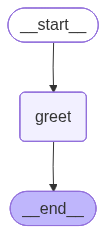

In [3]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [ ]:
result = app.invoke({"name": "Mahendra", "yoe": 9})
print(result)

In [ ]:
result["final"]

## Exercise: Sequential Graph

Your task:
1. Accept a user’s name, yoe, and a list of their skills.
2. Pass the state through three nodes that:
    - First node: Personalizes the name field with a greeting.
    - Second node: Describes the user’s yoe.
    - Third node: Lists the user’s skills in a formatted string.
3. The final output in the result field should be a combined message in this format:

![Exercise_Sequential_graph](Exercise_Sequential_graph.png)

In [ ]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

# ── State ──────────────────────────────────────────────────────────────────────
class ProfileState(TypedDict):
    name: str
    yoe: int
    skills: list[str]
    final: str

# ── Tool (plain Python function) ───────────────────────────────────────────────
def format_skills(skills: list[str]) -> str:
    """Tool: formats a list of skills into a readable string."""
    return ", ".join(skills)

# ── Nodes ──────────────────────────────────────────────────────────────────────
def greet_node(state: ProfileState) -> ProfileState:
    """Node 1: Personalize with a greeting."""
    state["final"] = f"Hello, {state['name']}! "
    return state

def experience_node(state: ProfileState) -> ProfileState:
    """Node 2: Describe years of experience."""
    state["final"] += f"You have {state['yoe']} year(s) of experience. "
    return state

def skills_node(state: ProfileState) -> ProfileState:
    """Node 3: Calls the format_skills tool to list skills."""
    skills_str = format_skills(state["skills"])   # ← tool call
    state["final"] += f"Your skills include: {skills_str}."
    return state

# ── Build the Sequential Graph ─────────────────────────────────────────────────
seq_graph = StateGraph(ProfileState)

seq_graph.add_node("Greet",      greet_node)
seq_graph.add_node("Experience", experience_node)
seq_graph.add_node("Skills",     skills_node)

seq_graph.add_edge(START,        "Greet")
seq_graph.add_edge("Greet",      "Experience")
seq_graph.add_edge("Experience", "Skills")
seq_graph.add_edge("Skills",     END)

seq_app = seq_graph.compile()
print("✅ Sequential graph compiled")


In [ ]:

# ── Visualize the sequential graph ────────────────────────────────────────────
from IPython.display import Image, display
display(Image(seq_app.get_graph().draw_mermaid_png()))


In [ ]:

# ── Run the sequential graph ───────────────────────────────────────────────────
result = seq_app.invoke({
    "name": "Ashwini",
    "yoe": 7,
    "skills": ["Python", "LangGraph", "Machine Learning"],
    "final": ""
})

print(result["final"])


# Adding Tools to Agents

At its core, a **tool is just a plain Python function** — a piece of logic a node can call to do something specific.

In LangGraph, a **node wraps a tool**: it reads what it needs from state, calls the function, and writes the result back to state.

**Pattern:**
```
plain Python function  →  wrapped by a node  →  node connected to graph via router
```

Below we build a calculator agent with four tools (add, subtract, multiply, divide).  
The router reads `state["operation"]` and routes to the matching node — each node calls exactly one tool.

In [ ]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display

# ── State ──────────────────────────────────────────────────────────────────────
class CalcState(TypedDict):
    a:         float
    b:         float
    operation: str    # "add" | "subtract" | "multiply" | "divide"
    result:    str

# ── Tools — plain Python functions ────────────────────────────────────────────
def add(a: float, b: float) -> str:
    return f"{a} + {b} = {a + b}"

def subtract(a: float, b: float) -> str:
    return f"{a} - {b} = {a - b}"

def multiply(a: float, b: float) -> str:
    return f"{a} × {b} = {a * b}"

def divide(a: float, b: float) -> str:
    if b == 0:
        return "Error: cannot divide by zero"
    return f"{a} ÷ {b} = {a / b}"

print("✅ State and tool functions defined")

In [ ]:
# ── Nodes — each node calls exactly one tool ──────────────────────────────────
# The node's job: read inputs from state, call the tool, write result back to state

def add_node(state: CalcState) -> CalcState:
    state["result"] = add(state["a"], state["b"])
    return state

def subtract_node(state: CalcState) -> CalcState:
    state["result"] = subtract(state["a"], state["b"])
    return state

def multiply_node(state: CalcState) -> CalcState:
    state["result"] = multiply(state["a"], state["b"])
    return state

def divide_node(state: CalcState) -> CalcState:
    state["result"] = divide(state["a"], state["b"])
    return state

print("✅ Nodes defined — each wraps one tool")

In [ ]:
# ── Router — reads state["operation"] and returns the matching node name ───────
# Returns a string, never modifies state

def operation_router(state: CalcState) -> str:
    return state["operation"]   # "add" | "subtract" | "multiply" | "divide"

print("✅ Router defined")

In [ ]:
calc_graph = StateGraph(CalcState)

# Register all four tool-nodes
calc_graph.add_node("add",      add_node)
calc_graph.add_node("subtract", subtract_node)
calc_graph.add_node("multiply", multiply_node)
calc_graph.add_node("divide",   divide_node)

# Router fires at START and picks the right node
calc_graph.add_conditional_edges(
    START,
    operation_router,
    {
        "add":      "add",
        "subtract": "subtract",
        "multiply": "multiply",
        "divide":   "divide",
    }
)

# Every tool-node leads to END
calc_graph.add_edge("add",      END)
calc_graph.add_edge("subtract", END)
calc_graph.add_edge("multiply", END)
calc_graph.add_edge("divide",   END)

calc_app = calc_graph.compile()
display(Image(calc_app.get_graph().draw_mermaid_png()))
# You should see START fork into 4 branches — one per tool

In [ ]:
test_cases = [
    {"a": 25,  "b": 17,  "operation": "add",      "result": ""},
    {"a": 100, "b": 40,  "operation": "subtract",  "result": ""},
    {"a": 6,   "b": 9,   "operation": "multiply",  "result": ""},
    {"a": 144, "b": 12,  "operation": "divide",    "result": ""},
]

for state in test_cases:
    result = calc_app.invoke(state)
    print(f"operation={state['operation']:10} → {result['result']}")

## Exercise — Add a Fifth Tool

Add a `modulo` tool that returns the remainder of `a ÷ b`.

**Steps:**
1. Write a plain `modulo(a, b)` function
2. Write a `modulo_node` that calls it and writes to `state["result"]`
3. Add the node to the graph and wire it up (`"modulo": "modulo"` in the path_map)
4. Test: `{"a": 17, "b": 5, "operation": "modulo", "result": ""}`

# Conditional Graph

In [ ]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

In [ ]:
class AgentState(TypedDict):
    number1: int
    operation: str # "add" or "subtract"
    number2: int
    finalNumber: int

In [ ]:
def adder(state: AgentState) -> AgentState:
    """
    This node adds 2 numbers.
    """
    print(state)
    state["finalNumber"] = state["number1"] + state["number2"]
    return state

In [ ]:
def subtractor(state: AgentState) -> AgentState:
    """
    This node subtracts 2 numbers.
    """
    print(state)
    state["finalNumber"] = state["number1"] - state["number2"]
    return state

In [ ]:
def decide_next_node(state: AgentState) -> str:
    """
    This node decides which operation to perform.
    """
    if state["operation"] == "add":
        return "addition_operation"
    elif state["operation"] == "subtract":
        return "subtraction_operation"
    else:
        raise ValueError("Invalid operation")
    
# Notice that no state is returned here

In [ ]:
graph = StateGraph(AgentState)

graph.add_node("add_node", adder)
graph.add_node("subtract_node", subtractor)

graph.add_node("router", lambda state:state) # passthrough function (meaning i/p node state is same as o/p state)

graph.add_edge(START, "router")
graph.add_conditional_edges(
    source="router",
    path=decide_next_node,
    path_map={
        # Format -> Edge: Node
        "addition_operation": "add_node",
        "subtraction_operation": "subtract_node"
    }
)

graph.add_edge("add_node", END)
graph.add_edge("subtract_node", END)

app = graph.compile()

In [ ]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [ ]:
initial_state = AgentState(
    number1=10,
    operation="subtract",
    number2=4,
    finalNumber=0,
)

In [ ]:
result = app.invoke(initial_state)
print(result)

In [ ]:
# Another way to do the same thing
result = app.invoke({"number1": 10, "operation": "subtract", "number2": 4, "finalNumber": 0})
print(result)

## Exercise: Conditional Graph

**Your task:**

- Make the graph shown below! You will need to make use of 2 
conditional edges!

**Input**: initial_state = AgentState(number1 = 10, operation="-", 
number2 = 5, number3 = 7, number4=2, operation2="+", 
finalNumber= 0, finalNumber2 = 0)

![Exercise_Conditional_graph](Exercise_Conditional_graph.png)

# Looping Graph

In [ ]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Dict, List
import random

In [ ]:
class AgentState(TypedDict):
    name: str
    number: List[int]   # Store random numbers
    counter: int

In [ ]:
def greeting_node(state: AgentState) -> AgentState:
    """
    This node greets the user.
    """
    state["name"] = f"Hello {state['name']}!"
    state["counter"] = 0    # to handle negative numbers
    return state

def random_number_node(state: AgentState) -> AgentState:
    """
    This node generates a random number.
    """
    print(f"State at start of random_number_node: {state}")
    state["number"].append(random.randint(1, 10))
    state["counter"] += 1
    print(f"State at end of random_number_node: {state}")
    return state

def should_continue_node(state: AgentState) -> str:
    """
    This node decides whether to continue or not.
    """
    if state["counter"] < 5:
        print(f"Entering loop: {state['counter']}")
        return "loop"   # loop edge - continue looping
    else:
        return "exit"   # exit edge - stop looping

In [ ]:
# greeting -> random -> random....  -> END

In [ ]:
graph = StateGraph(AgentState)

graph.add_node("greeting", greeting_node)
graph.add_node("random_number", random_number_node)

graph.add_edge("greeting", "random_number")

graph.add_conditional_edges(
    source="random_number",
    path=should_continue_node,
    path_map={
        # Format -> Edge: Node
        "loop": "random_number",    # Self-loop
        "exit": END                 # End Graph
    }
)

graph.set_entry_point("greeting")

app = graph.compile()

In [ ]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [ ]:
initial_state = AgentState(name="Mahendra", number=[], counter=0)

In [ ]:
app.invoke(initial_state)
print(initial_state)

In [ ]:
result = app.invoke(initial_state)
print(result)

## Exercise: Looping Graph

**Your task:**

- Make the graph shown below! You need to implement an Automatic Higher or Lower 
Game. 
- Set the bounds to between 1 to 20. The Graph has to keep guessing (max number of 
guesses is 7) where if the guess is correct, then it stops, but if not we keep looping until 
we hit the max limit of 7. 
- Each time a number is guessed, the hint node should say higher or lower and the graph 
should account for this information and guess the next guess accordingly. 

- **Input**: {"player_name": "Student", "guesses": [], "attempts": 0, "lower_bound": 1, 
"upper_bound": 20}

**Hint**: It will need to adjust its bounds after every guess based on the hint provided by the 
hint node

![Exercise_Looping_graph](Exercise_Looping_graph.png)

# Adding Memory to agents

In [ ]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, List, Dict
from pathlib import Path
import json
import datetime

In [ ]:
class ConversationState(TypedDict):
    user_name: str
    conversation_history: List[Dict[str, str]]  # Memory component
    current_message: str
    response: str
    user_preferences: List[str]  # Long-term memory (append-only)
    session_count: int

In [ ]:
PREFERENCES_FILE = Path("user_preferences.json")
PREFERENCE_KEYWORDS = ["favorite", "favourite", "prefer", "preference", "love", "like"]


def load_user_preferences() -> List[str]:
    if not PREFERENCES_FILE.exists():
        return []

    try:
        with PREFERENCES_FILE.open("r", encoding="utf-8") as file:
            data = json.load(file)

        if isinstance(data, list):
            return [str(item) for item in data]

        # Backward compatibility for previously saved dict format.
        if isinstance(data, dict):
            return [f"{key}: {value}" for key, value in data.items()]
    except (json.JSONDecodeError, OSError):
        pass

    return []


def save_user_preferences(preferences: List[str]) -> None:
    try:
        with PREFERENCES_FILE.open("w", encoding="utf-8") as file:
            json.dump(preferences, file, indent=2)
    except OSError:
        print("Warning: Unable to persist user preferences.")


def memory_processor_node(state: ConversationState) -> ConversationState:
    """
    Process and store conversation in memory
    """
    # Add current message to conversation history (Short-term memory)
    state["conversation_history"].append({
        "timestamp": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        "user": state["current_message"],
        "type": "user_input"
    })

    # Update session count
    state["session_count"] += 1

    print(f"Memory updated. Total interactions: {len(state['conversation_history'])}")
    return state


def response_generator_node(state: ConversationState) -> ConversationState:
    """
    Generate response using memory context
    """
    # Use conversation history to generate context-aware response
    history_count = len(state["conversation_history"])

    if history_count == 1:
        state["response"] = f"Hello {state['user_name']}! Nice to meet you. How can I help you today?"
    elif history_count <= 3:
        state["response"] = f"I remember we've talked {history_count} times. What would you like to discuss now?"
    else:
        # Reference previous conversations (using memory)
        prev_topics = [msg["user"] for msg in state["conversation_history"][-3:] if msg["type"] == "user_input"]
        state["response"] = f"We've had {history_count} interactions. Recently you mentioned: {', '.join(prev_topics[-2:])}. What's next?"

    # Store response in memory
    state["conversation_history"].append({
        "timestamp": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        "agent": state["response"],
        "type": "agent_response"
    })

    return state


def preference_learner_node(state: ConversationState) -> ConversationState:
    """
    Learn and store user preferences (Long-term memory, append-only)
    """
    loaded_preferences = load_user_preferences()

    # Merge loaded and in-memory preferences without duplicates.
    merged_preferences = list(loaded_preferences)
    for pref in state["user_preferences"]:
        if pref not in merged_preferences:
            merged_preferences.append(pref)
    state["user_preferences"] = merged_preferences

    message = state["current_message"].strip()
    normalized_message = message.lower()

    if any(keyword in normalized_message for keyword in PREFERENCE_KEYWORDS):
        user_preference = message
        if user_preference not in state["user_preferences"]:
            state["user_preferences"].append(user_preference)
            save_user_preferences(state["user_preferences"])
            print(f"Appended user_preference: {user_preference}")
        else:
            print(f"Preference already stored: {user_preference}")
    elif len(state["user_preferences"]) > 0:
        print(f"Current preferences: {state['user_preferences']}")

    return state

In [ ]:
# Build the memory-enabled conversation graph
memory_graph = StateGraph(ConversationState)

memory_graph.add_node("memory_processor", memory_processor_node)
memory_graph.add_node("preference_learner", preference_learner_node)
memory_graph.add_node("response_generator", response_generator_node)

# Flow: memory -> preferences -> response
memory_graph.add_edge(START, "memory_processor")
memory_graph.add_edge("memory_processor", "preference_learner")
memory_graph.add_edge("preference_learner", "response_generator")
memory_graph.add_edge("response_generator", END)

memory_app = memory_graph.compile()

In [ ]:
from IPython.display import Image, display
display(Image(memory_app.get_graph().draw_mermaid_png()))

In [ ]:
# Test the memory-enabled agent with multiple interactions
conversation_state = ConversationState(
    user_name="Alice",
    conversation_history=[],
    current_message="Hello, I'm new here",
    response="",
    user_preferences=load_user_preferences(),
    session_count=0
)

print(f"Loaded saved preferences: {conversation_state['user_preferences']}")
print()

# First interaction
print("=== First Interaction ===")
result1 = memory_app.invoke(conversation_state)
save_user_preferences(result1["user_preferences"])
print(f"Agent: {result1['response']}")
print(f"Memory size: {len(result1['conversation_history'])}")
print()

In [ ]:
# Continue with the same state for memory continuity
result1["current_message"] = "My favorite color is blue"
print("=== Second Interaction ===")
result2 = memory_app.invoke(result1)
save_user_preferences(result2["user_preferences"])
print(f"Agent: {result2['response']}")
print(f"Memory size: {len(result2['conversation_history'])}")
print()

# Third interaction
result2["current_message"] = "I also love pizza"
print("=== Third Interaction ===")
result3 = memory_app.invoke(result2)
save_user_preferences(result3["user_preferences"])
print(f"Agent: {result3['response']}")
print(f"Memory size: {len(result3['conversation_history'])}")
print()

# Fourth interaction - agent should remember previous context
result3["current_message"] = "What did we discuss before?"
print("=== Fourth Interaction ===")
result4 = memory_app.invoke(result3)
save_user_preferences(result4["user_preferences"])
print(f"Agent: {result4['response']}")
print(f"Final Memory size: {len(result4['conversation_history'])}")
print(f"User preferences learned: {result4['user_preferences']}")

# Extended Memory Lab: All Four Memory Types

The original memory section above shows **Episodic memory** — conversation history (short-term) and preferences persisted to disk (long-term).

This extended section wires up **all four memory types** from the Agent Memory diagram:

| Memory Type | Implementation | Node |
|---|---|---|
| **Episodic — short-term** | `conversation_history` list in state | `memory_processor_node_v2` |
| **Episodic — long-term** | Preferences saved to `user_preferences_extended.json` | `preference_learner_node_v2` |
| **Semantic** | `KNOWLEDGE_BASE` + keyword retrieval (simulates vector search) | `semantic_retrieval_node` |
| **Procedural** | `PROMPT_REGISTRY` + `TOOL_REGISTRY` dicts | `procedural_loader_node` |
| **Working Memory** | Assembled context dict (prompt + tools + chunk + history) | `context_assembler_node` |

**Pipeline:**
```
START → procedural_loader → memory_processor → semantic_retrieval
      → preference_learner → context_assembler → response_generator → END
```

In [ ]:
from typing import TypedDict, List, Dict, Any

class ExtendedConversationState(TypedDict):
    """
    Expanded state that holds all four memory types:
      - conversation_history  → Episodic short-term (in-memory list)
      - user_preferences      → Episodic long-term  (persisted to JSON on disk)
      - system_prompt + available_tools → Procedural memory (loaded from registries)
      - retrieved_context     → Semantic memory     (fetched from knowledge base)
      - working_memory        → Working / context memory (assembled fresh each turn)
    """
    user_name:           str
    conversation_history: List[Dict[str, str]]   # Episodic short-term
    current_message:     str
    response:            str
    user_preferences:    List[str]               # Episodic long-term (disk-backed)
    session_count:       int
    persona:             str                     # selects row from Procedural registries
    system_prompt:       str                     # loaded by procedural_loader_node
    available_tools:     List[str]               # loaded by procedural_loader_node
    retrieved_context:   str                     # fetched by semantic_retrieval_node
    working_memory:      Dict[str, Any]          # assembled by context_assembler_node

print("✅ ExtendedConversationState defined")

In [ ]:
# ── Semantic Memory store ─────────────────────────────────────────────────────
# In production: replace with embeddings + vector DB (e.g. ChromaDB / Pinecone)
KNOWLEDGE_BASE = [
    {"topic": "leave policy",    "content": "Employees are entitled to 20 days of paid annual leave per year, plus 10 public holidays."},
    {"topic": "expense claims",  "content": "Expense claims must be submitted within 30 days of incurring the expense via the HR portal."},
    {"topic": "remote work",     "content": "Remote work is available for up to 3 days per week; core hours 10am–3pm must be observed."},
    {"topic": "learning budget", "content": "Each employee receives $1,500 annually for professional development and certifications."},
]

# ── Procedural Memory stores ──────────────────────────────────────────────────
# PROMPT_REGISTRY: persona → system prompt   (how to behave)
PROMPT_REGISTRY = {
    "default": "You are a helpful assistant. Be concise and friendly.",
    "support": "You are an HR support agent. Empathise with the employee first, then provide clear policy guidance.",
    "analyst": "You are a data analyst assistant. Prioritise precision; cite sources and use bullet points.",
}

# TOOL_REGISTRY: persona → list of available tools   (what you can do)
TOOL_REGISTRY = {
    "default": ["search_knowledge_base"],
    "support": ["search_knowledge_base", "check_leave_balance", "submit_hr_ticket"],
    "analyst": ["search_knowledge_base", "query_database", "generate_report"],
}

print("✅ KNOWLEDGE_BASE, PROMPT_REGISTRY, TOOL_REGISTRY defined")
print(f"   Knowledge chunks : {len(KNOWLEDGE_BASE)}")
print(f"   Prompt personas  : {list(PROMPT_REGISTRY.keys())}")
print(f"   Tool personas    : {list(TOOL_REGISTRY.keys())}")

In [ ]:
# ─── Node 1: Procedural Loader (Procedural Memory) ───────────────────────────
def procedural_loader_node(state: ExtendedConversationState) -> ExtendedConversationState:
    """
    Reads the PROMPT_REGISTRY and TOOL_REGISTRY for the current persona.
    This is Procedural Memory: the agent's 'how to behave' knowledge.
    """
    persona = state.get("persona", "default")
    state["system_prompt"]  = PROMPT_REGISTRY.get(persona, PROMPT_REGISTRY["default"])
    state["available_tools"] = TOOL_REGISTRY.get(persona, TOOL_REGISTRY["default"])
    print(f"  🔧 Procedural Memory: persona='{persona}' | "
          f"prompt loaded | tools={state['available_tools']}")
    return state


# ─── Node 3: Semantic Retrieval (Semantic Memory) ────────────────────────────
def semantic_retrieval_node(state: ExtendedConversationState) -> ExtendedConversationState:
    """
    Keyword-based retrieval from KNOWLEDGE_BASE — simulates a vector-store ANN search.
    In production, swap the keyword match for embeddings + cosine similarity.
    """
    query = state["current_message"].lower()
    matched = [
        chunk["content"] for chunk in KNOWLEDGE_BASE
        if any(word in query for word in chunk["topic"].split())
    ]
    state["retrieved_context"] = matched[0] if matched else "No relevant policy found."
    result_label = "✓ match" if matched else "✗ no match"
    print(f"  🔍 Semantic Memory ({result_label}): '{state['retrieved_context'][:60]}…'")
    return state

print("✅ procedural_loader_node and semantic_retrieval_node defined")

In [ ]:
# ─── Node 5: Context Assembler (Working Memory) ──────────────────────────────
def context_assembler_node(state: ExtendedConversationState) -> ExtendedConversationState:
    """
    Assembles Working Memory — the snapshot the LLM actually sees for this turn.
    Combines: system prompt (Procedural), available tools (Procedural),
              retrieved chunk (Semantic), recent history (Episodic short-term).
    """
    state["working_memory"] = {
        "system_prompt":     state.get("system_prompt", ""),
        "available_tools":   state.get("available_tools", []),
        "retrieved_context": state.get("retrieved_context", ""),
        "recent_history":    state["conversation_history"][-4:],   # sliding window
    }
    tools_str = ", ".join(state["working_memory"]["available_tools"])
    print(f"  📋 Working Memory: prompt set | tools=[{tools_str}] | "
          f"context={'yes' if state['working_memory']['retrieved_context'] != 'No relevant policy found.' else 'none'} | "
          f"history_window={len(state['working_memory']['recent_history'])}")
    return state

print("✅ context_assembler_node defined")

In [ ]:
PREFERENCES_FILE_V2 = Path("user_preferences_extended.json")

# ─── Node 2: Memory Processor v2 (Episodic Short-term) ───────────────────────
def memory_processor_node_v2(state: ExtendedConversationState) -> ExtendedConversationState:
    """Stores current message in conversation history (Episodic short-term memory)."""
    state["conversation_history"].append({
        "timestamp": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        "user": state["current_message"],
        "type": "user_input"
    })
    state["session_count"] += 1
    print(f"  🧠 Episodic (short-term): {len(state['conversation_history'])} entries in history")
    return state


# ─── Node 4: Preference Learner v2 (Episodic Long-term) ──────────────────────
def preference_learner_node_v2(state: ExtendedConversationState) -> ExtendedConversationState:
    """Detects preference keywords and persists them to disk (Episodic long-term memory)."""
    PREFERENCE_KEYWORDS = ["favorite", "favourite", "prefer", "love", "like"]
    message = state["current_message"].strip()
    if any(kw in message.lower() for kw in PREFERENCE_KEYWORDS):
        if message not in state["user_preferences"]:
            state["user_preferences"].append(message)
            try:
                with PREFERENCES_FILE_V2.open("w") as f:
                    json.dump(state["user_preferences"], f, indent=2)
                print(f"  💾 Episodic (long-term): preference saved → '{message}'")
            except OSError:
                pass
    return state


# ─── Node 6: Response Generator v2 (reads assembled working_memory) ──────────
def response_generator_node_v2(state: ExtendedConversationState) -> ExtendedConversationState:
    """
    Generates a response using the assembled working_memory.
    In a real agent this working_memory dict would be serialised into the LLM prompt.
    """
    wm = state["working_memory"]
    retrieved = wm.get("retrieved_context", "")
    recent = [m["user"] for m in wm.get("recent_history", []) if m.get("type") == "user_input"]
    history_count = len(state["conversation_history"])

    if history_count == 1:
        base = f"Hello {state['user_name']}! Nice to meet you. How can I help?"
    elif retrieved and retrieved != "No relevant policy found.":
        base = f"Based on our knowledge base: {retrieved}"
    elif recent:
        base = f"We've had {history_count} exchanges. You asked about: {', '.join(recent[-2:])}."
    else:
        base = f"I remember our {history_count} interactions — what can I help with?"

    tools_preview = ', '.join(wm.get('available_tools', [])[:2])
    state["response"] = base + f" [Persona: {state['persona']} | Tools: {tools_preview}]"

    state["conversation_history"].append({
        "timestamp": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        "agent": state["response"],
        "type": "agent_response"
    })
    return state

print("✅ memory_processor_node_v2, preference_learner_node_v2, response_generator_node_v2 defined")

In [ ]:
# 🏗️ Build the Extended Memory Graph — all four memory types wired together

extended_graph = StateGraph(ExtendedConversationState)

extended_graph.add_node("procedural_loader",  procedural_loader_node)   # Procedural Memory
extended_graph.add_node("memory_processor",   memory_processor_node_v2) # Episodic Short-term
extended_graph.add_node("semantic_retrieval", semantic_retrieval_node)   # Semantic Memory
extended_graph.add_node("preference_learner", preference_learner_node_v2)# Episodic Long-term
extended_graph.add_node("context_assembler",  context_assembler_node)    # Working Memory
extended_graph.add_node("response_generator", response_generator_node_v2)# LLM Response

extended_graph.add_edge(START,                 "procedural_loader")
extended_graph.add_edge("procedural_loader",   "memory_processor")
extended_graph.add_edge("memory_processor",    "semantic_retrieval")
extended_graph.add_edge("semantic_retrieval",  "preference_learner")
extended_graph.add_edge("preference_learner",  "context_assembler")
extended_graph.add_edge("context_assembler",   "response_generator")
extended_graph.add_edge("response_generator",  END)

extended_app = extended_graph.compile()

print("✅ Extended memory graph compiled!")
print("\nPipeline:")
print("  START → procedural_loader  [Procedural Memory  — loads prompt + tools]")
print("        → memory_processor   [Episodic Short-term — stores message in history]")
print("        → semantic_retrieval [Semantic Memory     — retrieves knowledge chunk]")
print("        → preference_learner [Episodic Long-term  — detects + persists prefs]")
print("        → context_assembler  [Working Memory      — assembles LLM context]")
print("        → response_generator [Response            — reads working_memory]")
print("        → END")

In [ ]:
# 🎨 Visualize the extended memory graph
# Each node maps directly to a memory type from the deck's Agent Memory diagram
from IPython.display import Image, display
display(Image(extended_app.get_graph().draw_mermaid_png()))
# 👆 You should see 6 nodes — one per memory function in the pipeline

### 🚀 Running the Extended Memory Agent

We run **five interactions**, varying the `persona` between turns to show Procedural Memory switching in real time.

Watch each turn's printed output:
- 🔧 Which **prompt and tools** were loaded — Procedural Memory
- 🔍 What was **retrieved** from the knowledge base — Semantic Memory
- 🧠 How many **history entries** are in context — Episodic Memory
- 📋 The assembled **Working Memory** before the response is generated

In [ ]:
# Load any previously saved extended preferences
try:
    saved_prefs = json.loads(PREFERENCES_FILE_V2.read_text()) if PREFERENCES_FILE_V2.exists() else []
except Exception:
    saved_prefs = []

extended_state = ExtendedConversationState(
    user_name="Alice",
    conversation_history=[],
    current_message="",
    response="",
    user_preferences=saved_prefs,
    session_count=0,
    persona="support",
    system_prompt="",
    available_tools=[],
    retrieved_context="",
    working_memory={}
)

interactions = [
    ("Hello, I'm new here",             "support"),
    ("What is the leave policy?",       "support"),
    ("My favorite tool is Python",      "support"),
    ("How do I submit expense claims?", "analyst"),
    ("What have we discussed so far?",  "support"),
]

result = extended_state
for i, (message, persona) in enumerate(interactions, 1):
    result = dict(result)
    result["current_message"] = message
    result["persona"] = persona
    print(f"\n{'='*60}")
    print(f"💬 Interaction {i}: \"{message}\"  (persona={persona})")
    print(f"{'='*60}")
    result = extended_app.invoke(result)
    print(f"\n🤖 Response : {result['response']}")
    print(f"📊 History  : {len(result['conversation_history'])} entries | Prefs: {result['user_preferences']}")

print(f"\n{'='*60}")
print("✅ Session complete — all four memory types demonstrated.")
print(f"💾 Persistent preferences saved: {result['user_preferences']}")